In [1]:
import numpy as np
import jax, jax.numpy as jnp

In [2]:
d = np.load("particles.npz")
p0  = np.stack([d["x_0"], d["y_0"]], -1).astype(np.float32)     # (N, 2)
pos = np.stack([d["x_t"], d["y_t"]], -1).astype(np.float32)     # (N, T, 2)
vel = np.stack([d["v_xt"], d["v_yt"]], -1).astype(np.float32)   # (N, T, 2)
N, T, _ = pos.shape

idx = np.random.default_rng(0).permutation(N)
n_val = N // 10
tr, va = idx[n_val:], idx[:n_val]

pos_mu = pos[tr].reshape(-1, 2).mean(0)
pos_sd = pos[tr].reshape(-1, 2).std(0) + 1e-8
vel_sd = vel[tr].reshape(-1, 2).std(0) + 1e-8

def prep(i):
    start = np.zeros((len(i), T, 2), np.float32)
    start[:, 0] = (p0[i] - pos_mu) / pos_sd                 # start position only at t=0
    u = np.concatenate([vel[i] / vel_sd, start], -1)        # (n, T, 4)
    y = (pos[i] - pos_mu) / pos_sd
    return jnp.asarray(u), jnp.asarray(y)

u_tr, y_tr = prep(tr)
u_va, y_va = prep(va)
print(u_tr.shape, y_tr.shape, u_va.shape, y_va.shape)

(9000, 150, 4) (9000, 150, 2) (1000, 150, 4) (1000, 150, 2)


# We Want To
> Add noise to some trials

# Defining the Model
$$
h_t = \tanh(W_{h~\text{in}} h_{t-1} + W_x x_t + b_h) ~~~~~~~~~~~~~~ \hat{y} = W_{h~\text{out}} h_t
$$

In [3]:
def init_params(key, n_in=4, H=128, n_out=2, g=0.9):
    k1, k2, k3 = jax.random.split(key, 3)
    
    # Normal Initialization for W_x
    W_x = jax.random.normal(k1, (H, n_in)) * np.sqrt(1/n_in)
    W_hh = g * jax.random.normal(k2, (H, H)) * np.sqrt(1/H)
    b_h = jax.random.normal(k3, (H,)) * np.sqrt(1/H)

    # Decoders
    W_out = jax.random.normal(k3, (n_out, H)) * np.sqrt(1/H)
    b_out = jnp.zeros(n_out)

    return {"W_hh": W_hh, "W_x": W_x, "b_h": b_h, "W_out": W_out, "b_out": b_out}

# RNN Forward Pass
def rnn_forward(params, u):
    def step(h, u_t):
        h = jnp.tanh(params["W_hh"] @ h + params["W_x"] @ u_t + params["b_h"])
        return h, h

    _, hs = jax.lax.scan(step, jnp.zeros(params["W_hh"].shape[0]), u)
    return hs, hs @ params["W_out"].T + params["b_out"]

batched_forward = jax.vmap(rnn_forward, in_axes=(None, 0))

# We will define many loss functions: L2 Norm
def loss_fn(params, u, y):
    _, y_hat = batched_forward(params, u)
    return jnp.mean((y_hat - y) ** 2)



In [10]:
import optax

key = jax.random.PRNGKey(0)
g = 0.9

params = init_params(key)
opt = optax.sgd(learning_rate=1e-3)
opt_state = opt.init(params)

@jax.jit
def train_step(params, opt_state, u, y):
    loss, grads = jax.value_and_grad(loss_fn)(params, u, y)
    updates, opt_state = opt.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

W_hh_init = params["W_hh"]
eval_loss = jax.jit(loss_fn)

EIGEN_COUNT = 100

In [ ]:
import time

steps, batch = 3000, 128
history = []
t0 = time.time()

for step in range(1, steps + 1):
    key, k = jax.random.split(key)
    b = jax.random.randint(k, (batch,), 0, u_tr.shape[0])
    params, opt_state, loss = train_step(params, opt_state, u_tr[b], y_tr[b])

    if step % 250 == 0 or step == 1:
        val = float(eval_loss(params, u_va, y_va))
        drift = float(jnp.linalg.norm(params["W_hh"] - W_hh_init))
        history.append((step, float(loss), val, drift))
        print(f"step {step:5d} | train {float(loss):.4f} | val {val:.4f} | "
              f"drift {drift:.4f}")

    if step % EIGEN_COUNT == 0 or step == 1:
        ev = np.linalg.eigvals(np.asarray(params["W_hh"]))
        history.append((step, float(loss), val, drift, ev))

step     1 | train 0.3478 | val 0.3099 | drift 0.7872
step   250 | train 0.2785 | val 0.2621 | drift 0.8412
step   500 | train 0.1948 | val 0.2036 | drift 0.8897
step   750 | train 0.1896 | val 0.1801 | drift 0.9258
step  1000 | train 0.1613 | val 0.1562 | drift 0.9602
step  1250 | train 0.1436 | val 0.1414 | drift 0.9912
step  1500 | train 0.1280 | val 0.1255 | drift 1.0167
step  1750 | train 0.1127 | val 0.1171 | drift 1.0406
step  2000 | train 0.0968 | val 0.1079 | drift 1.0612
step  2250 | train 0.0908 | val 0.1002 | drift 1.0804
step  2500 | train 0.1018 | val 0.0990 | drift 1.0976
step  2750 | train 0.0863 | val 0.0892 | drift 1.1139
step  3000 | train 0.1158 | val 0.0873 | drift 1.1291


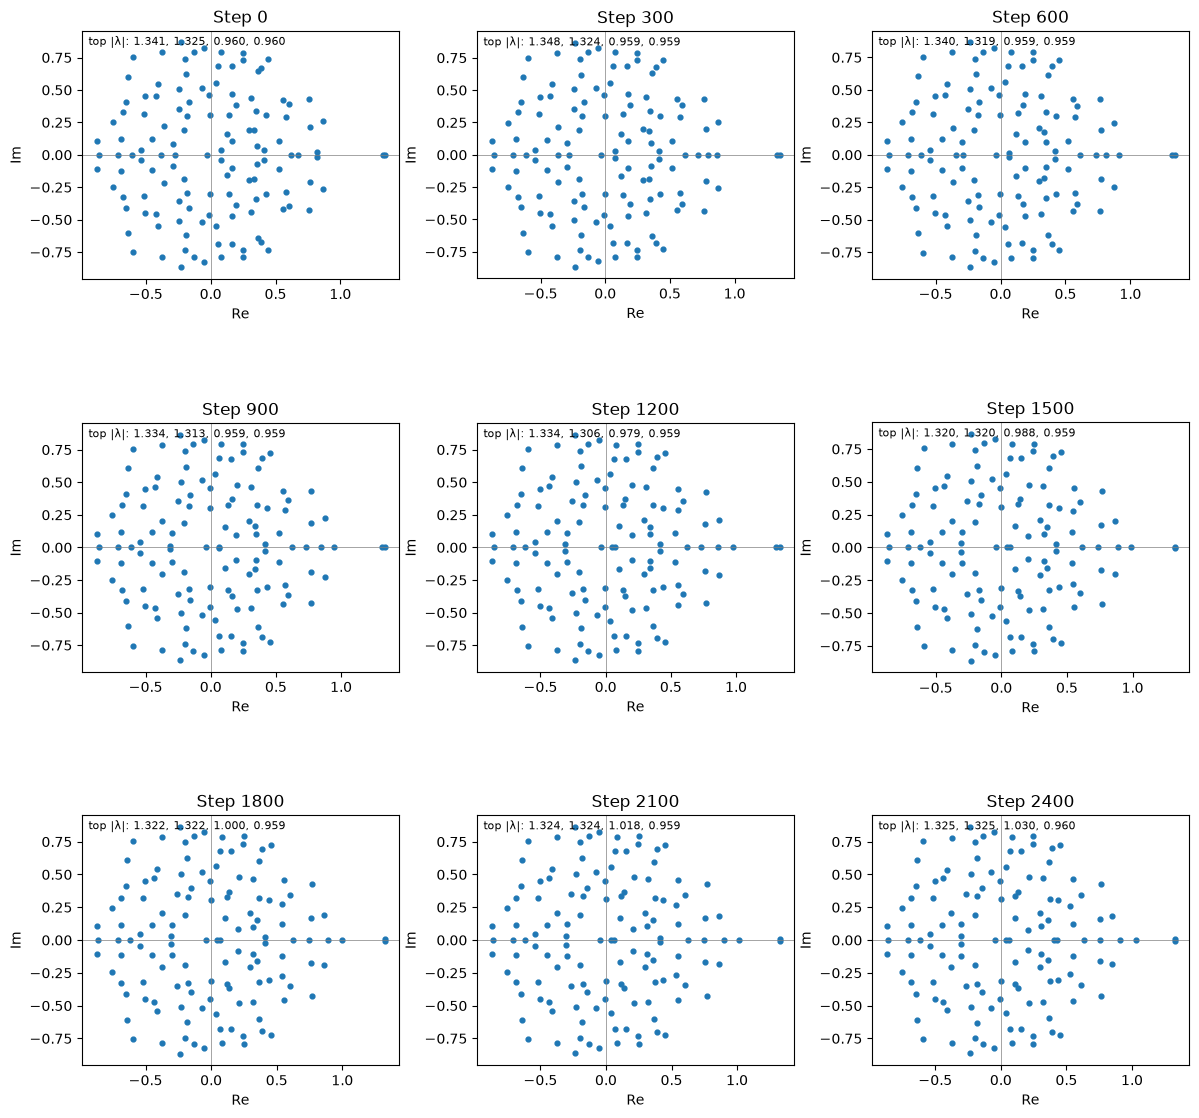

In [ ]:
import matplotlib.pyplot as plt

# Assuming 'history' is already defined in your environment
eigenvalues = [hist[-1] for hist in history if len(hist) == 5]

# Create a 3x3 grid and flatten the axes array for easy iteration
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes_flat = axes.flatten()

# Safely determine step size and indices (up to 9 subplots max)
step = max(1, len(eigenvalues) // 9)
indices = list(range(0, len(eigenvalues), step))[:9]

for i, idx in enumerate(indices):
    if i >= len(axes_flat):
        break
    
    ax = axes_flat[i]  # Get the specific subplot axis
    ev = eigenvalues[idx]
    
    ax.scatter(ev.real, ev.imag, s=12)
    ax.axhline(0, c="gray", lw=0.5)
    ax.axvline(0, c="gray", lw=0.5)
    ax.set_aspect("equal")
    ax.set_title(f"Step {idx * EIGEN_COUNT}")
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    
    top = np.sort(np.abs(ev))[::-1][:4]
    ax.text(0.02, 0.98, "top |λ|: " + ", ".join(f"{v:.3f}" for v in top),
            transform=ax.transAxes, va="top", fontsize=8)  # Added closing parenthesis

plt.tight_layout()
plt.show()